In [ ]:
# ============================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================

# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset loading
from sklearn.datasets import load_iris

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Visualization configuration
sns.set_style('whitegrid')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# ============================================
# STEP 2: LOAD THE DATASET
# ============================================

# Load Iris dataset
iris = load_iris()

In [ ]:
print(iris.DESCR[:1000])

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [ ]:
# ============================================
# STEP 3: CONVERT DATASET INTO DATAFRAME
# ============================================

# Create DataFrame containing input features
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

In [ ]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [ ]:
# Add target column
df['species'] = iris.target

In [ ]:
# Convert numerical labels into species names
df['species'] = df['species'].map(
    dict(enumerate(iris.target_names))
)

In [ ]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
df.tail(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [ ]:
df.shape

(150, 5)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [ ]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [ ]:
df.isnull()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
145,False,False,False,False,False
146,False,False,False,False,False
147,False,False,False,False,False
148,False,False,False,False,False


In [ ]:
df.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species,0


In [ ]:
df.duplicated().sum()

np.int64(1)

In [ ]:
df['species'].value_counts()

,count
species,
setosa,50
versicolor,50
virginica,50


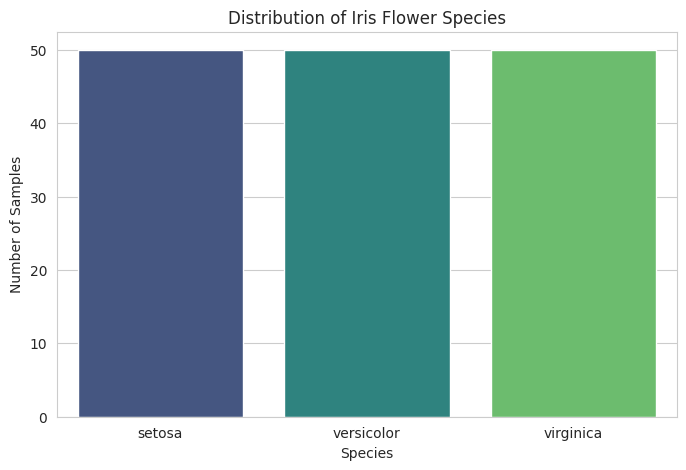

In [ ]:
# ============================================
# STEP 1: SPECIES DISTRIBUTION
# ============================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='species',
    hue='species',
    palette='viridis',
    legend=False
)

plt.title('Distribution of Iris Flower Species')
plt.xlabel('Species')
plt.ylabel('Number of Samples')
plt.show()

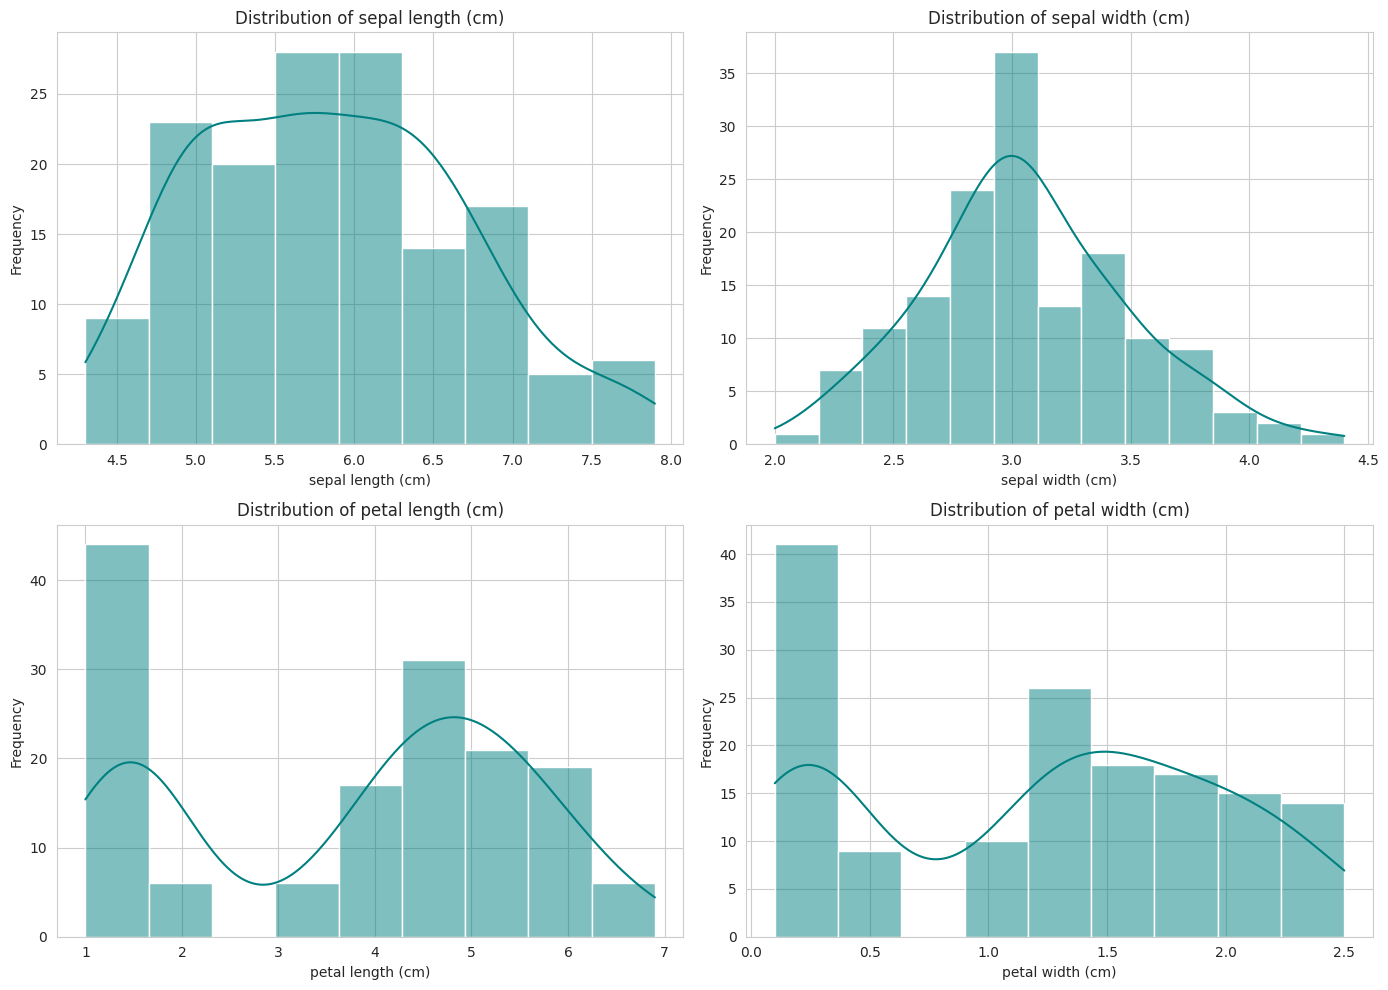

In [ ]:

# ============================================
# STEP 2: FEATURE DISTRIBUTION
# ============================================

features = iris.feature_names

plt.figure(figsize=(14, 10))

for i, feature in enumerate(features):
    plt.subplot(2, 2, i + 1)

    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        color='teal'
    )

    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


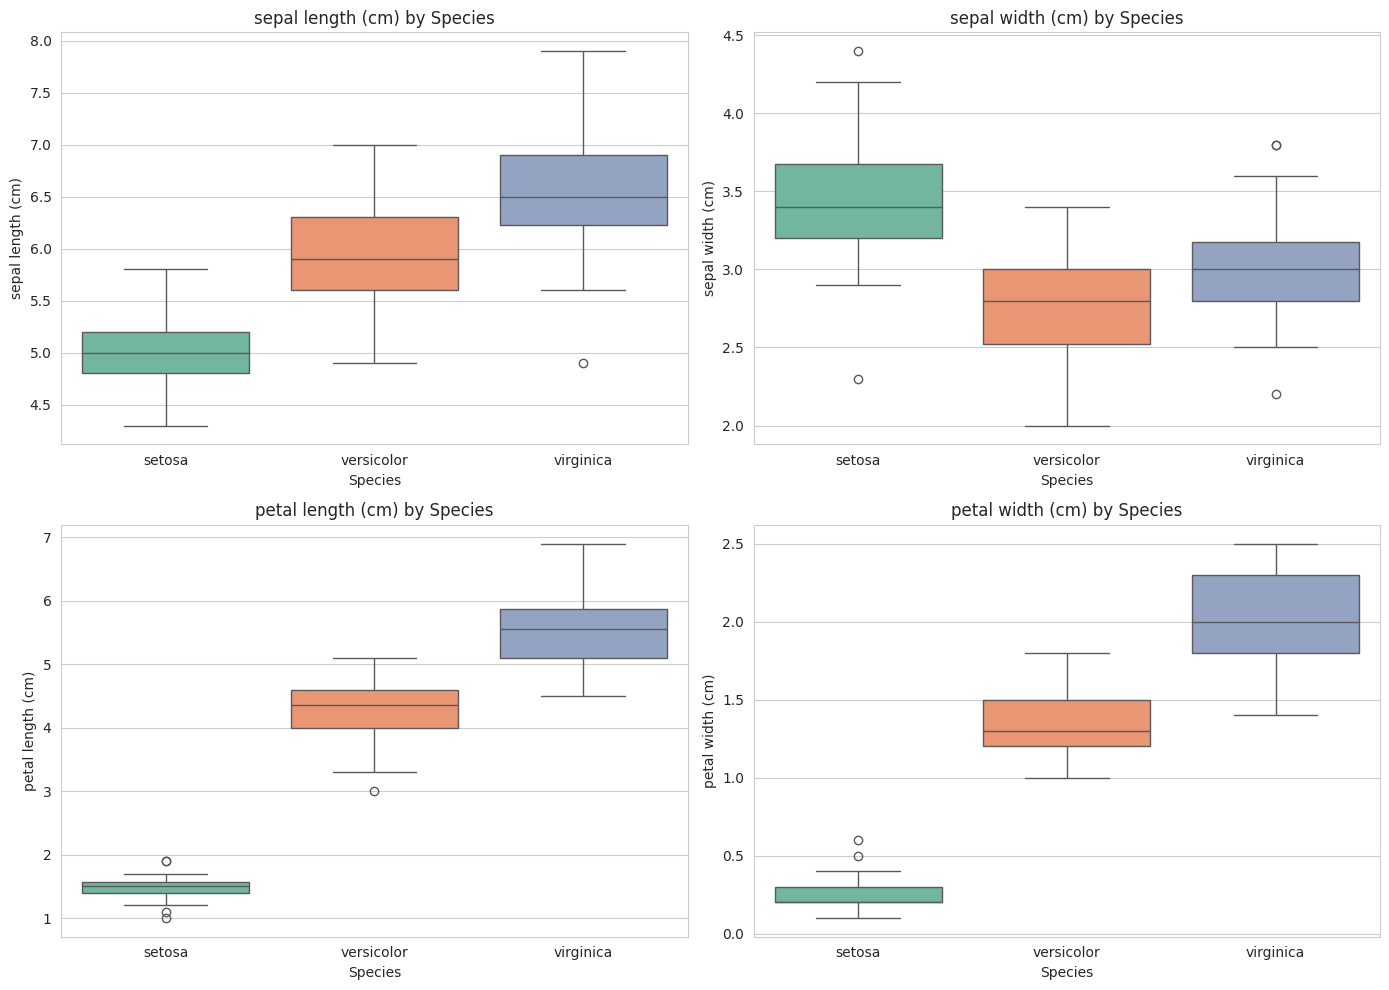

In [ ]:

# ============================================
# STEP 3: FEATURE COMPARISON USING BOXPLOTS
# ============================================

plt.figure(figsize=(14, 10))

for i, feature in enumerate(features):
    plt.subplot(2, 2, i + 1)

    sns.boxplot(
        data=df,
        x='species',
        y=feature,
        hue='species',
        palette='Set2',
        legend=False
    )

    plt.title(f'{feature} by Species')
    plt.xlabel('Species')
    plt.ylabel(feature)

plt.tight_layout()
plt.show()


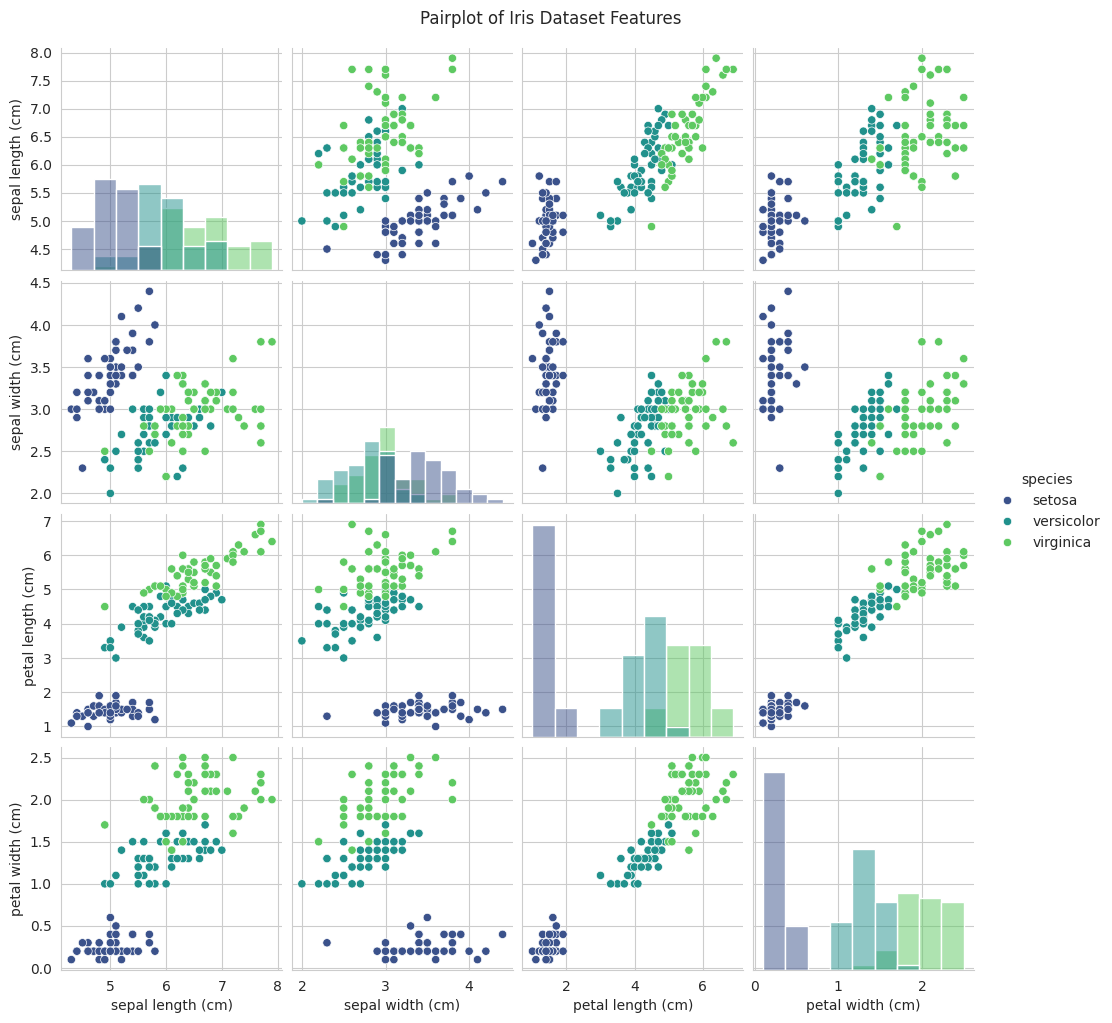

In [ ]:

# ============================================
# STEP 4: PAIRPLOT ANALYSIS
# ============================================

sns.pairplot(
    df,
    hue='species',
    palette='viridis',
    diag_kind='hist',
    height=2.5
)

plt.suptitle(
    'Pairplot of Iris Dataset Features',
    y=1.02
)

plt.show()


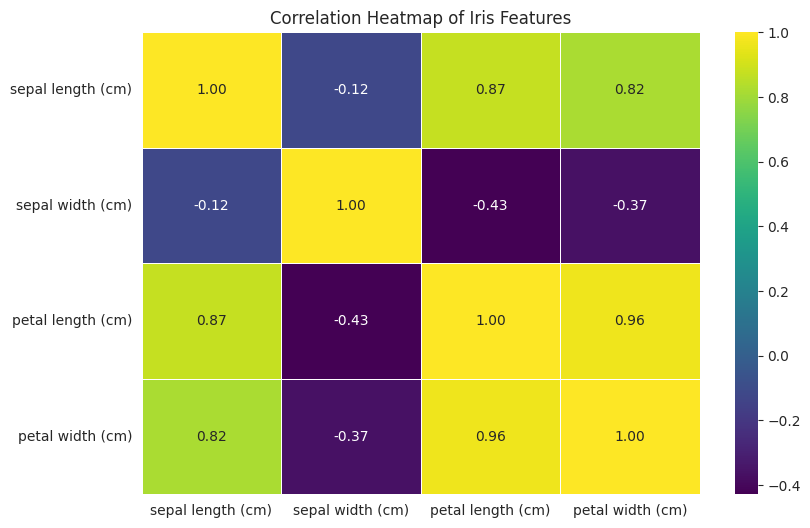

In [ ]:

# ============================================
# STEP 5: CORRELATION HEATMAP
# ============================================

# Calculate correlation between numerical features
correlation = df[features].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='viridis',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Iris Features')
plt.show()


In [ ]:

# ============================================
# STEP 1: SEPARATE FEATURES AND TARGET
# ============================================

# Independent variables (input features)
X = df.drop('species', axis=1)

print(X.head())
print(X.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
(150, 4)


In [ ]:
# Dependent variable (target)
y = df['species']

print(y.head())
print(y.shape)

0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object
(150,)


In [ ]:

# ============================================
# STEP 2: TRAIN-TEST SPLITTING
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Features: (120, 4)
Testing Features: (30, 4)
Training Labels: (120,)
Testing Labels: (30,)


In [ ]:
print("Training Set Distribution:")
print(y_train.value_counts())

print("\nTesting Set Distribution:")
print(y_test.value_counts())

Training Set Distribution:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing Set Distribution:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [ ]:
# ============================================
# STEP 1: FEATURE SCALING
# ============================================

# Initialize StandardScaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [ ]:
# ============================================
# STEP 2: VERIFY SCALED DATA
# ============================================

# Convert scaled training data into DataFrame
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X.columns
)

# Display first five scaled observations
print("Scaled Training Data:")
display(X_train_scaled_df.head())

Scaled Training Data:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-1.721568,-0.332101,-1.345722,-1.323276
1,-1.124492,-1.227655,0.414505,0.651763
2,1.144395,-0.555990,0.584850,0.256755
3,-1.124492,0.115676,-1.288941,-1.454945
4,-0.408002,-1.227655,0.130598,0.125086


In [ ]:
# Check mean of scaled training features
print("Mean of Scaled Features:")
print(X_train_scaled_df.mean())

# Check standard deviation
print("\nStandard Deviation of Scaled Features:")
print(X_train_scaled_df.std(ddof=0))

Mean of Scaled Features:
sepal length (cm)   -1.208293e-15
sepal width (cm)    -2.036797e-15
petal length (cm)    4.996004e-16
petal width (cm)     1.674586e-15
dtype: float64

Standard Deviation of Scaled Features:
sepal length (cm)    1.0
sepal width (cm)     1.0
petal length (cm)    1.0
petal width (cm)     1.0
dtype: float64


In [ ]:
print("Original Training Shape:", X_train.shape)
print("Scaled Training Shape:", X_train_scaled.shape)

print("\nOriginal Testing Shape:", X_test.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Original Training Shape: (120, 4)
Scaled Training Shape: (120, 4)

Original Testing Shape: (30, 4)
Scaled Testing Shape: (30, 4)


In [ ]:
# ============================================
# STEP 1: INITIALIZE KNN CLASSIFIER
# ============================================

# Import KNN classifier
from sklearn.neighbors import KNeighborsClassifier

# Initialize the model with K = 5
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

print("KNN model initialized successfully!")

KNN model initialized successfully!


In [ ]:
# ============================================
# STEP 2: TRAIN THE KNN MODEL
# ============================================

# Train the model using scaled training data
knn_model.fit(
    X_train_scaled,
    y_train
)

print("KNN model trained successfully!")

KNN model trained successfully!


In [ ]:
# ============================================
# STEP 3: MAKE PREDICTIONS
# ============================================

# Predict flower species using testing data
y_pred = knn_model.predict(X_test_scaled)

# Display first 10 predictions
print("First 10 Predictions:")
print(y_pred[:10])

# Display actual species
print("\nActual Species:")
print(y_test.iloc[:10].values)

First 10 Predictions:
[np.str_('setosa') np.str_('virginica') np.str_('versicolor')
 np.str_('versicolor') np.str_('setosa') np.str_('versicolor')
 np.str_('setosa') np.str_('setosa') np.str_('virginica')
 np.str_('versicolor')]

Actual Species:
[np.str_('setosa') np.str_('virginica') np.str_('versicolor')
 np.str_('versicolor') np.str_('setosa') np.str_('versicolor')
 np.str_('setosa') np.str_('setosa') np.str_('virginica')
 np.str_('versicolor')]


In [ ]:
# ============================================
# STEP 4: COMPARE ACTUAL AND PREDICTED VALUES
# ============================================

comparison = pd.DataFrame({
    'Actual Species': y_test.values,
    'Predicted Species': y_pred
})

display(comparison.head(10))

,Actual Species,Predicted Species
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


In [ ]:
# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.9333333333333333
Accuracy Percentage: 93.33333333333333 %


In [ ]:
# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=iris.target_names
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


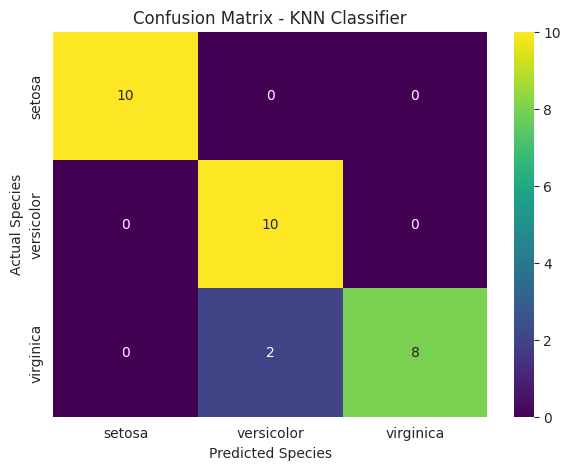

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='viridis',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title('Confusion Matrix - KNN Classifier')
plt.xlabel('Predicted Species')
plt.ylabel('Actual Species')
plt.show()

In [ ]:
# Generate classification report
report = classification_report(y_test, y_pred)

print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [ ]:
# ============================================
# STEP 1: INITIALIZE KNN CLASSIFIER
# ============================================

# Import KNN classifier
from sklearn.neighbors import KNeighborsClassifier

# Initialize the model with K = 10
knn_model = KNeighborsClassifier(
    n_neighbors=10
)

print("KNN model initialized successfully!")

KNN model initialized successfully!


In [ ]:
# ============================================
# STEP 2: TRAIN THE KNN MODEL
# ============================================

# Train the model using scaled training data
knn_model.fit(
    X_train_scaled,
    y_train
)

print("KNN model trained successfully!")

KNN model trained successfully!


In [ ]:
# ============================================
# STEP 3: MAKE PREDICTIONS
# ============================================

# Predict flower species using testing data
y_pred = knn_model.predict(X_test_scaled)

# Display first 10 predictions
print("First 10 Predictions:")
print(y_pred[:10])

# Display actual species
print("\nActual Species:")
print(y_test.iloc[:10].values)

First 10 Predictions:
[np.str_('setosa') np.str_('virginica') np.str_('versicolor')
 np.str_('versicolor') np.str_('setosa') np.str_('versicolor')
 np.str_('setosa') np.str_('setosa') np.str_('virginica')
 np.str_('versicolor')]

Actual Species:
[np.str_('setosa') np.str_('virginica') np.str_('versicolor')
 np.str_('versicolor') np.str_('setosa') np.str_('versicolor')
 np.str_('setosa') np.str_('setosa') np.str_('virginica')
 np.str_('versicolor')]


In [ ]:
# ============================================
# STEP 4: COMPARE ACTUAL AND PREDICTED VALUES
# ============================================

comparison = pd.DataFrame({
    'Actual Species': y_test.values,
    'Predicted Species': y_pred
})

display(comparison.head(10))

,Actual Species,Predicted Species
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


In [ ]:
# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.9666666666666667
Accuracy Percentage: 96.66666666666667 %


In [ ]:
# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=iris.target_names
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


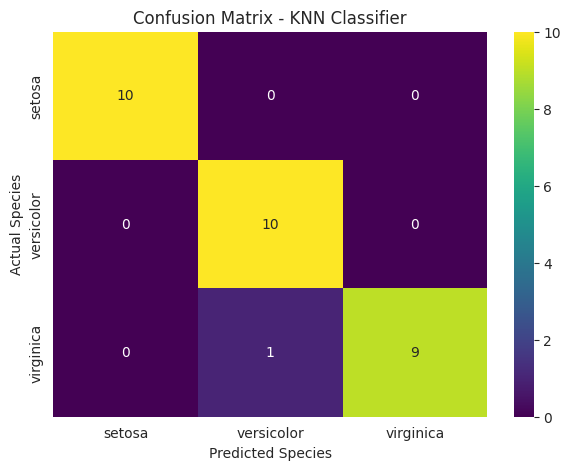

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='viridis',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title('Confusion Matrix - KNN Classifier')
plt.xlabel('Predicted Species')
plt.ylabel('Actual Species')
plt.show()

In [ ]:
# Generate classification report
report = classification_report(y_test, y_pred)

print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

